# 2. Modifier Challenges (NF-κB / IκB Pathway)

These three challenges are **genuinely hard** — give them a real try, use the **Hint** dropdowns when you want a clue, and don't hesitate to talk to Simon when you get stuck!

For every challenge below, the code cell starts with the **original unmodified model** so you can build the changes yourself step by step.

First, load the Julia packages.

In [1]:
using DifferentialEquations
using Plots
using CSV
using DataFrames

gr()
println("Ready for Tutorial 2 challenges!")

Ready for Tutorial 2 challenges!


---

## Challenge 1: Stop `IkB` increasing forever

In our first modifier model, `IkB` climbs upward forever because there is nothing removing it!

**Your task:** Add reactions for the **basal expression** and **degradation** of `IkB` (refer back to how constant expression and mass-action degradation were modelled in Tutorial 1) so that `IkB` settles to a realistic steady state!

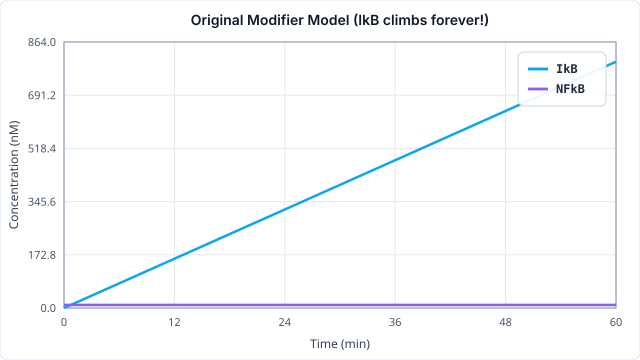

In [2]:
# Starting point: original modifier model where IkB climbs forever — edit to solve Challenge 1!
write("ratelaws_t2c1.csv", """
Rate Law Name      , Rate Law Definition
Induced Expression , {k1} * ([Mod1] / ({k2} + [Mod1]))
""")

write("reactions_t2c1.csv", """
Substrate , Products , Kinetic Law        , Modifiers , Parameters
          , IkB      , Induced Expression , NFkB      , k1_IkBexp k2_IkBexp
""")

write("parameters_t2c1.csv", """
Parameter , Value
k1_IkBexp , 20
k2_IkBexp , 5
""")

# Display your edited CSV table(s) cleanly below
display(CSV.read("ratelaws_t2c1.csv", DataFrame; stripwhitespace=true))
display(CSV.read("reactions_t2c1.csv", DataFrame; stripwhitespace=true))
display(CSV.read("parameters_t2c1.csv", DataFrame; stripwhitespace=true))

run(`python3 csv2model-multiscale.py reactions_t2c1.csv parameters_t2c1.csv ratelaws_t2c1.csv modModel_t2c1.jl`)
include("modModel_t2c1.jl")
include("variableNames.jl")
println("Species: ", syms)

y0_c1 = [0.0, 10.0]  # [IkB, NFkB]
prob_c1 = ODEProblem(ODEFunction(modModel_t2c1), y0_c1, (0.0, 60.0))
sol_c1 = solve(prob_c1, abstol=1e-5, reltol=1e-3)

plot(
    sol_c1,
    label = permutedims(syms),
    xlabel = "Time (min)",
    ylabel = "Concentration (nM)",
    title = "Challenge 1: Stop IkB Increasing Forever",
    lw = 2.5,
)

```{admonition} Hint
:class: dropdown tip

You need to update all three CSV tables:
1. **`ratelaws_t2c1.csv`**: Bring back `Constant Exp` (`{k1}`) and `Mass Action with substrate` (`[S1] * {k1}`) from Tutorial 1.
2. **`reactions_t2c1.csv`**: Add one row for basal expression of `IkB` (empty substrate, product `IkB`) and one row for degradation of `IkB` (substrate `IkB`, empty product).
3. **`parameters_t2c1.csv`**: Give numerical values to your new basal expression and degradation parameters (e.g. `k1_IkBbasal = 0.5`, `k1_IkBdeg = 0.2`).
```

````{admonition} Reveal Solution
:class: dropdown note

1. Add `Constant Exp` and `Mass Action with substrate` to `ratelaws_t2c1.csv`.
2. Add basal synthesis (`,IkB,Constant Exp,,k1_IkBbasal`) and degradation (`IkB,,Mass Action with substrate,,k1_IkBdeg`) to `reactions_t2c1.csv`.
3. Add `k1_IkBbasal,0.5` and `k1_IkBdeg,0.2` to `parameters_t2c1.csv`.
4. Re-run the cell — `IkB` now rises smoothly and levels off at a finite steady state!

```julia
write("ratelaws_t2c1.csv", """
Rate Law Name              , Rate Law Definition
Constant Exp               , {k1}
Mass Action with substrate , [S1] * {k1}
Induced Expression         , {k1} * ([Mod1] / ({k2} + [Mod1]))
""")

write("reactions_t2c1.csv", """
Substrate , Products , Kinetic Law                , Modifiers , Parameters
          , IkB      , Induced Expression         , NFkB      , k1_IkBexp k2_IkBexp
          , IkB      , Constant Exp               ,           , k1_IkBbasal
IkB       ,          , Mass Action with substrate ,           , k1_IkBdeg
""")

write("parameters_t2c1.csv", """
Parameter   , Value
k1_IkBexp   , 20
k2_IkBexp   , 5
k1_IkBbasal , 0.5
k1_IkBdeg   , 0.2
""")

# Display your edited CSV table(s) cleanly below
display(CSV.read("ratelaws_t2c1.csv", DataFrame; stripwhitespace=true))
display(CSV.read("reactions_t2c1.csv", DataFrame; stripwhitespace=true))
display(CSV.read("parameters_t2c1.csv", DataFrame; stripwhitespace=true))

run(`python3 csv2model-multiscale.py reactions_t2c1.csv parameters_t2c1.csv ratelaws_t2c1.csv modModel_t2c1.jl`)
include("modModel_t2c1.jl")
include("variableNames.jl")
println("Species: ", syms)

y0_c1 = [0.0, 10.0]  # [IkB, NFkB]
prob_c1 = ODEProblem(ODEFunction(modModel_t2c1), y0_c1, (0.0, 60.0))
sol_c1 = solve(prob_c1, abstol=1e-5, reltol=1e-3)

plot(
    sol_c1,
    label = permutedims(syms),
    xlabel = "Time (min)",
    ylabel = "Concentration (nM)",
    title = "Challenge 1 Solution: IkB Reaches Steady State",
    lw = 2.5,
)
```
````

---

## Challenge 2: Model `NFkB` and `IkB` binding and unbinding

In real cells, `IkB` is the **inhibitor of NF-κB** — it binds directly to `NFkB` to form an inactive **`NFkB_IkB`** complex, creating a negative feedback loop!

```{figure} ../images/nfkb-ikb-binding.svg
:alt: Reversible binding and unbinding of NFkB and IkB into NFkB_IkB complex
:width: 100%

Model reversible binding as **two separate reactions**: binding (`NFkB + IkB → NFkB_IkB`) and unbinding (`NFkB_IkB → NFkB + IkB`).
```

**Your task:** Starting from the steady-state `IkB` model below, add **binding** and **unbinding** between `NFkB` and `IkB`!

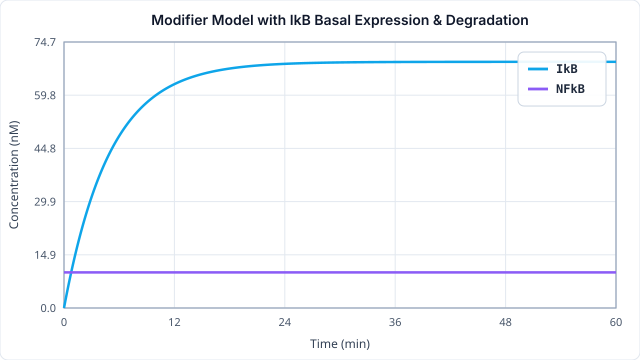

In [3]:
# Starting point: IkB steady-state model (without binding) — edit to solve Challenge 2!
write("ratelaws_t2c2.csv", """
Rate Law Name              , Rate Law Definition
Constant Exp               , {k1}
Mass Action with substrate , [S1] * {k1}
Induced Expression         , {k1} * ([Mod1] / ({k2} + [Mod1]))
""")

write("reactions_t2c2.csv", """
Substrate , Products , Kinetic Law                , Modifiers , Parameters
          , IkB      , Induced Expression         , NFkB      , k1_IkBexp k2_IkBexp
          , IkB      , Constant Exp               ,           , k1_IkBbasal
IkB       ,          , Mass Action with substrate ,           , k1_IkBdeg
""")

write("parameters_t2c2.csv", """
Parameter   , Value
k1_IkBexp   , 20
k2_IkBexp   , 5
k1_IkBbasal , 0.5
k1_IkBdeg   , 0.2
""")

# Display your edited CSV table(s) cleanly below
display(CSV.read("ratelaws_t2c2.csv", DataFrame; stripwhitespace=true))
display(CSV.read("reactions_t2c2.csv", DataFrame; stripwhitespace=true))
display(CSV.read("parameters_t2c2.csv", DataFrame; stripwhitespace=true))

run(`python3 csv2model-multiscale.py reactions_t2c2.csv parameters_t2c2.csv ratelaws_t2c2.csv modModel_t2c2.jl`)
include("modModel_t2c2.jl")
include("variableNames.jl")
println("Species: ", syms)

y0_c2 = [0.0, 10.0]
prob_c2 = ODEProblem(ODEFunction(modModel_t2c2), y0_c2, (0.0, 60.0))
sol_c2 = solve(prob_c2, abstol=1e-5, reltol=1e-3)

plot(
    sol_c2,
    label = permutedims(syms),
    xlabel = "Time (min)",
    ylabel = "Concentration (nM)",
    title = "Challenge 2: Add NFkB + IkB Binding & Unbinding",
    lw = 2.5,
)

```{admonition} Hint
:class: dropdown tip

1. Add a new rate law with **two substrates** for binding: `[S1] * [S2] * {kon}` (remember parameters use **curly braces `{}`** in `CSV2Model`!).
2. For unbinding, you can reuse `Mass Action with substrate` (`[S1] * {k1}`).
3. In `reactions_t2c2.csv`, separate multiple substrates or multiple products with a **space**: e.g. `NFkB IkB` as substrates for binding (product: `NFkB_IkB`), and `NFkB_IkB` as substrate for unbinding (products: `NFkB IkB`).
4. Don't forget to add a 3rd initial condition (`0.0`) to `y0_c2` for `NFkB_IkB`!
```

````{admonition} Reveal Solution
:class: dropdown note

1. Add `Mass Action Binding,[S1] * [S2] * {kon}` to `ratelaws_t2c2.csv`.
2. Add two reactions to `reactions_t2c2.csv`:
   - Binding: `NFkB IkB,NFkB_IkB,Mass Action Binding,,kon_NFkBIkB`
   - Unbinding: `NFkB_IkB,NFkB IkB,Mass Action with substrate,,k1_NFkBIkBoff`
3. Add `kon_NFkBIkB,0.5` and `k1_NFkBIkBoff,0.05` to `parameters_t2c2.csv`.
4. Update `y0_c2 = [0.0, 10.0, 0.0]` for `["IkB", "NFkB", "NFkB_IkB"]`.
5. Notice what happens when you run it: as `NFkB` induces `IkB`, the newly made `IkB` binds free `NFkB` into `NFkB_IkB`, pulling free `NFkB` back down — negative feedback in action!

```julia
write("ratelaws_t2c2.csv", """
Rate Law Name              , Rate Law Definition
Constant Exp               , {k1}
Mass Action with substrate , [S1] * {k1}
Induced Expression         , {k1} * ([Mod1] / ({k2} + [Mod1]))
Mass Action Binding        , [S1] * [S2] * {kon}
""")

write("reactions_t2c2.csv", """
Substrate , Products , Kinetic Law                , Modifiers , Parameters
          , IkB      , Induced Expression         , NFkB      , k1_IkBexp k2_IkBexp
          , IkB      , Constant Exp               ,           , k1_IkBbasal
IkB       ,          , Mass Action with substrate ,           , k1_IkBdeg
NFkB IkB  , NFkB_IkB , Mass Action Binding        ,           , kon_NFkBIkB
NFkB_IkB  , NFkB IkB , Mass Action with substrate ,           , k1_NFkBIkBoff
""")

write("parameters_t2c2.csv", """
Parameter     , Value
k1_IkBexp     , 20
k2_IkBexp     , 5
k1_IkBbasal   , 0.5
k1_IkBdeg     , 0.2
kon_NFkBIkB   , 0.5
k1_NFkBIkBoff , 0.05
""")

# Display your edited CSV table(s) cleanly below
display(CSV.read("ratelaws_t2c2.csv", DataFrame; stripwhitespace=true))
display(CSV.read("reactions_t2c2.csv", DataFrame; stripwhitespace=true))
display(CSV.read("parameters_t2c2.csv", DataFrame; stripwhitespace=true))

run(`python3 csv2model-multiscale.py reactions_t2c2.csv parameters_t2c2.csv ratelaws_t2c2.csv modModel_t2c2.jl`)
include("modModel_t2c2.jl")
include("variableNames.jl")
println("Species: ", syms)

y0_c2 = [0.0, 10.0, 0.0]  # [IkB, NFkB, NFkB_IkB]
prob_c2 = ODEProblem(ODEFunction(modModel_t2c2), y0_c2, (0.0, 60.0))
sol_c2 = solve(prob_c2, abstol=1e-5, reltol=1e-3)

plot(
    sol_c2,
    label = permutedims(syms),
    xlabel = "Time (min)",
    ylabel = "Concentration (nM)",
    title = "Challenge 2 Solution: NFkB–IkB Negative Feedback",
    lw = 2.5,
)
```
````

---

## Challenge 3: Add `IkB` mRNA (`NFkB` → `IkB_mRNA` → `IkB` protein)

`NFkB` doesn't directly synthesize `IkB` protein — it induces **`IkB` mRNA** (`IkB_mRNA`), which is then translated into **`IkB` protein**!

```{figure} ../images/nfkb-ikb-mrna.svg
:alt: NFkB induces IkB_mRNA transcription, and IkB_mRNA promotes IkB protein translation, with degradation of both
:width: 100%

Two-step gene expression with modifiers: `NFkB` promotes `IkB_mRNA` transcription, and `IkB_mRNA` promotes `IkB` protein translation (without either modifier being consumed!).
```

**Your task:** Add **`IkB_mRNA`** to the model so that `NFkB` induces `IkB_mRNA`, and `IkB_mRNA` promotes `IkB` protein expression (with degradation of both mRNA and protein, and optional `NFkB`–`IkB` binding!).

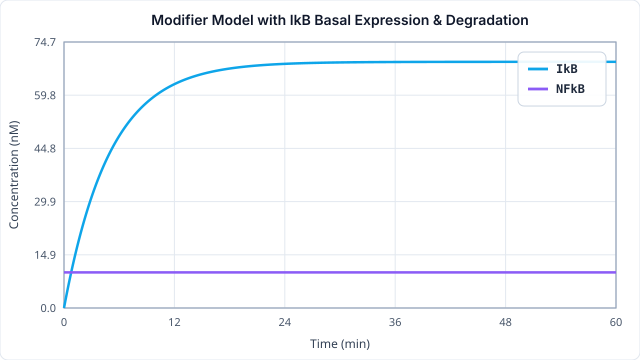

In [4]:
# Starting point: direct IkB induction model — edit this cell to add IkB_mRNA!
write("ratelaws_t2c3.csv", """
Rate Law Name              , Rate Law Definition
Constant Exp               , {k1}
Mass Action with substrate , [S1] * {k1}
Induced Expression         , {k1} * ([Mod1] / ({k2} + [Mod1]))
""")

write("reactions_t2c3.csv", """
Substrate , Products , Kinetic Law                , Modifiers , Parameters
          , IkB      , Induced Expression         , NFkB      , k1_IkBexp k2_IkBexp
          , IkB      , Constant Exp               ,           , k1_IkBbasal
IkB       ,          , Mass Action with substrate ,           , k1_IkBdeg
""")

write("parameters_t2c3.csv", """
Parameter   , Value
k1_IkBexp   , 20
k2_IkBexp   , 5
k1_IkBbasal , 0.5
k1_IkBdeg   , 0.2
""")

# Display your edited CSV table(s) cleanly below
display(CSV.read("ratelaws_t2c3.csv", DataFrame; stripwhitespace=true))
display(CSV.read("reactions_t2c3.csv", DataFrame; stripwhitespace=true))
display(CSV.read("parameters_t2c3.csv", DataFrame; stripwhitespace=true))

run(`python3 csv2model-multiscale.py reactions_t2c3.csv parameters_t2c3.csv ratelaws_t2c3.csv modModel_t2c3.jl`)
include("modModel_t2c3.jl")
include("variableNames.jl")
println("Species: ", syms)

y0_c3 = [0.0, 10.0]
prob_c3 = ODEProblem(ODEFunction(modModel_t2c3), y0_c3, (0.0, 60.0))
sol_c3 = solve(prob_c3, abstol=1e-5, reltol=1e-3)

plot(
    sol_c3,
    label = permutedims(syms),
    xlabel = "Time (min)",
    ylabel = "Concentration (nM)",
    title = "Challenge 3: Add IkB mRNA",
    lw = 2.5,
)

```{admonition} Hint
:class: dropdown tip

- Have **`NFkB`** act as the modifier promoting **`IkB_mRNA`** synthesis (using `Induced Expression`), plus a basal expression and degradation row for `IkB_mRNA`.
- Add a simple **`Translation`** rate law (`[Mod1] * {k1}`) where **`IkB_mRNA`** acts as the **modifier** producing **`IkB`** protein (remember: mRNA is not consumed by translation!).
- Make sure **both** `IkB_mRNA` and `IkB` have degradation reactions, and check the printed `syms` order before setting `y0_c3`!
```

````{admonition} Reveal Solution
:class: dropdown note

1. Add `Translation,[Mod1] * {k1}` (and `Mass Action Binding,[S1] * [S2] * {kon}` if including NF-κB/IκB binding) to `ratelaws_t2c3.csv`.
2. In `reactions_t2c3.csv`:
   - `NFkB` induces `IkB_mRNA` (`Induced Expression`), plus basal synthesis and decay of `IkB_mRNA`.
   - `IkB_mRNA` promotes `IkB` protein synthesis (`Translation`), plus `IkB` decay.
   - *(Bonus)* `NFkB` + `IkB` reversible binding into `NFkB_IkB`!
3. Add parameters for transcription, mRNA decay, translation, protein decay, and binding/unbinding.
4. Check `syms` (`["IkB_mRNA", "NFkB", "IkB", "NFkB_IkB"]`) and set `y0_c3 = [0.0, 10.0, 0.0, 0.0]` so we start with `10 nM` of `NFkB` and `0` of everything else.

```julia
write("ratelaws_t2c3.csv", """
Rate Law Name              , Rate Law Definition
Constant Exp               , {k1}
Mass Action with substrate , [S1] * {k1}
Induced Expression         , {k1} * ([Mod1] / ({k2} + [Mod1]))
Translation                , [Mod1] * {k1}
Mass Action Binding        , [S1] * [S2] * {kon}
""")

write("reactions_t2c3.csv", """
Substrate , Products , Kinetic Law                , Modifiers , Parameters
          , IkB_mRNA , Induced Expression         , NFkB      , k1_mRNAind k2_mRNAind
          , IkB_mRNA , Constant Exp               ,           , k1_mRNAbasal
IkB_mRNA  ,          , Mass Action with substrate ,           , k1_mRNAdeg
          , IkB      , Translation                , IkB_mRNA  , k1_IkBtrans
IkB       ,          , Mass Action with substrate ,           , k1_IkBdeg
NFkB IkB  , NFkB_IkB , Mass Action Binding        ,           , kon_NFkBIkB
NFkB_IkB  , NFkB IkB , Mass Action with substrate ,           , k1_NFkBIkBoff
""")

write("parameters_t2c3.csv", """
Parameter     , Value
k1_mRNAind    , 2.0
k2_mRNAind    , 5.0
k1_mRNAbasal  , 0.05
k1_mRNAdeg    , 0.1
k1_IkBtrans   , 5.0
k1_IkBdeg     , 0.2
kon_NFkBIkB   , 0.5
k1_NFkBIkBoff , 0.05
""")

# Display your edited CSV table(s) cleanly below
display(CSV.read("ratelaws_t2c3.csv", DataFrame; stripwhitespace=true))
display(CSV.read("reactions_t2c3.csv", DataFrame; stripwhitespace=true))
display(CSV.read("parameters_t2c3.csv", DataFrame; stripwhitespace=true))

run(`python3 csv2model-multiscale.py reactions_t2c3.csv parameters_t2c3.csv ratelaws_t2c3.csv modModel_t2c3.jl`)
include("modModel_t2c3.jl")
include("variableNames.jl")
println("Species: ", syms)

y0_c3 = [0.0, 10.0, 0.0, 0.0]  # [IkB_mRNA, NFkB, IkB, NFkB_IkB]
prob_c3 = ODEProblem(ODEFunction(modModel_t2c3), y0_c3, (0.0, 60.0))
sol_c3 = solve(prob_c3, abstol=1e-5, reltol=1e-3)

plot(
    sol_c3,
    label = permutedims(syms),
    xlabel = "Time (min)",
    ylabel = "Concentration (nM)",
    title = "Challenge 3 Solution: NFkB → IkB mRNA → IkB Protein Feedback",
    lw = 2.5,
)
```
````

Congratulations — you have just built the core **NF-κB / IκB transcriptional negative feedback module** in Julia!

Next, learn how **`CSV2Julia`** works in detail, how to build **time-dependent input curves**, and how to run our **published 101-species NF-κB model** in **[Tutorial 3: CSV2Julia Rules, Parameter Naming & Modes](../tutorial-3/01-csv2julia-rules-and-modes.ipynb)**.